<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES9-transient%20signal%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **The transient Universe**

7) Fit the same model from before with the same priors,  but this time use nested sampling.

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors (I used `ppf` from `scipy.stats.uniform`, but there are other ways to do it)

An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did earlier.

In [ ]:
import dynesty
import numpy as np
import matplotlib.pyplot as plt

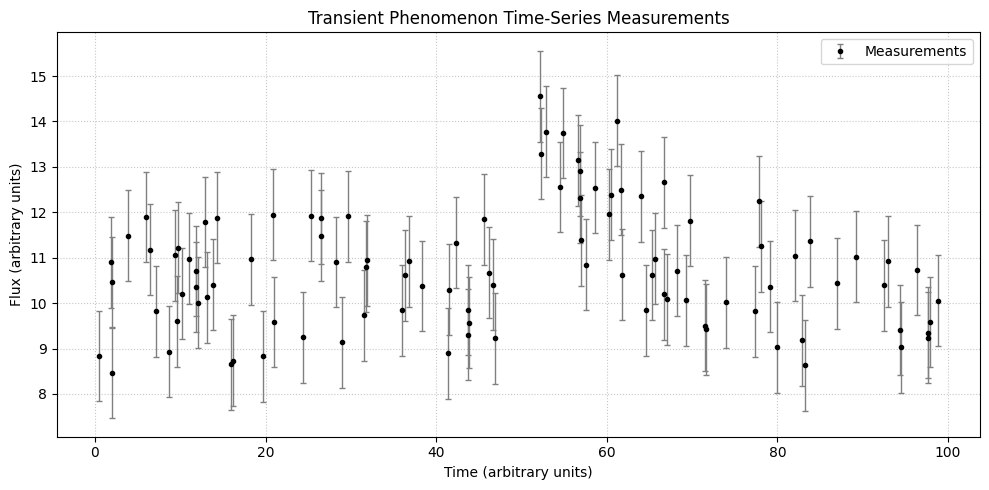

In [ ]:
data = np.load('transient.npy')
time = np.array(data[:, 0])
flux = np.array(data[:, 1])
sigma = np.array(data[:, 2]) #gaussian homoschedastic

#plot
fig, ax = plt.subplots(figsize=(10, 5))

plt.plot()
ax.errorbar(
    time,
    flux,
    yerr=sigma,
    fmt='.',
    color='black',
    ecolor='gray',
    elinewidth=1,
    capsize=2,
    label='Measurements'
)

ax.set_xlabel('Time (arbitrary units)')
ax.set_ylabel('Flux (arbitrary units)')
ax.set_title('Transient Phenomenon Time-Series Measurements')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
def model(t,theta):
#model definition 4-D
    b,A,t0,alpha=theta
    modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
    return modell

def logL(theta,y,t,sigma): #this parameter disposition is the one imposed by dynasty
#likelihood #need carefull normalizzation
  return -0.5*np.sum((((y-model(t,theta))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    '''b uniform in 0,50
       A uniform in 0,50
       t0 uniform in 0,100
       lnalpha uniform in -5,5
    '''
    u1, u2, u3, u4 = u
    p1 = 50.0 * u1   #b
    p2 = 50.0 * u2   #a
    p3 = 100.0 * u3  #t0
    p4 = np.exp(5*(2*u4-1)) #alpha

    theta_prior = np.array([p1, p2, p3,p4])
    return theta_prior



Running the sample

In [ ]:
# "Static" nested sampling.
labels = ['b','A','t0','alpha']
ndim = 4
sampler = dynesty.NestedSampler(logL, ptform, ndim,logl_args=[flux,time, sigma])
sampler.run_nested()
sresults = sampler.results

/tmp/ipykernel_1474/1008146846.py:4: RuntimeWarning: overflow encountered in exp
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
/tmp/ipykernel_1474/1008146846.py:4: RuntimeWarning: overflow encountered in multiply
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
 51%|█████     | 1811/3563 [00:02<00:05, 328.15it/s, bound: 0 | nc: 25 | ncall: 17781 | eff(%): 10.185 | loglstar: -268.647 | logz: -276.676 | dlogz: 105.706 >  0.509]/tmp/ipykernel_1474/1008146846.py:4: RuntimeWarning: overflow encountered in exp
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
/tmp/ipykernel_1474/1008146846.py:4: RuntimeWarning: overflow encountered in multiply
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
 50%|████▉     | 1920/3854 [00:03<00:07, 254.50it/s, bound: 1 | nc: 17 | ncall: 18684 | eff(%): 10.276 | loglstar: -244.025 | logz: -252.427 | dlogz: 81.275 >  0.509]/tmp/ipykernel_1474/1008146846.py:4: RuntimeWarning: overflow encountered in exp
  modell = n

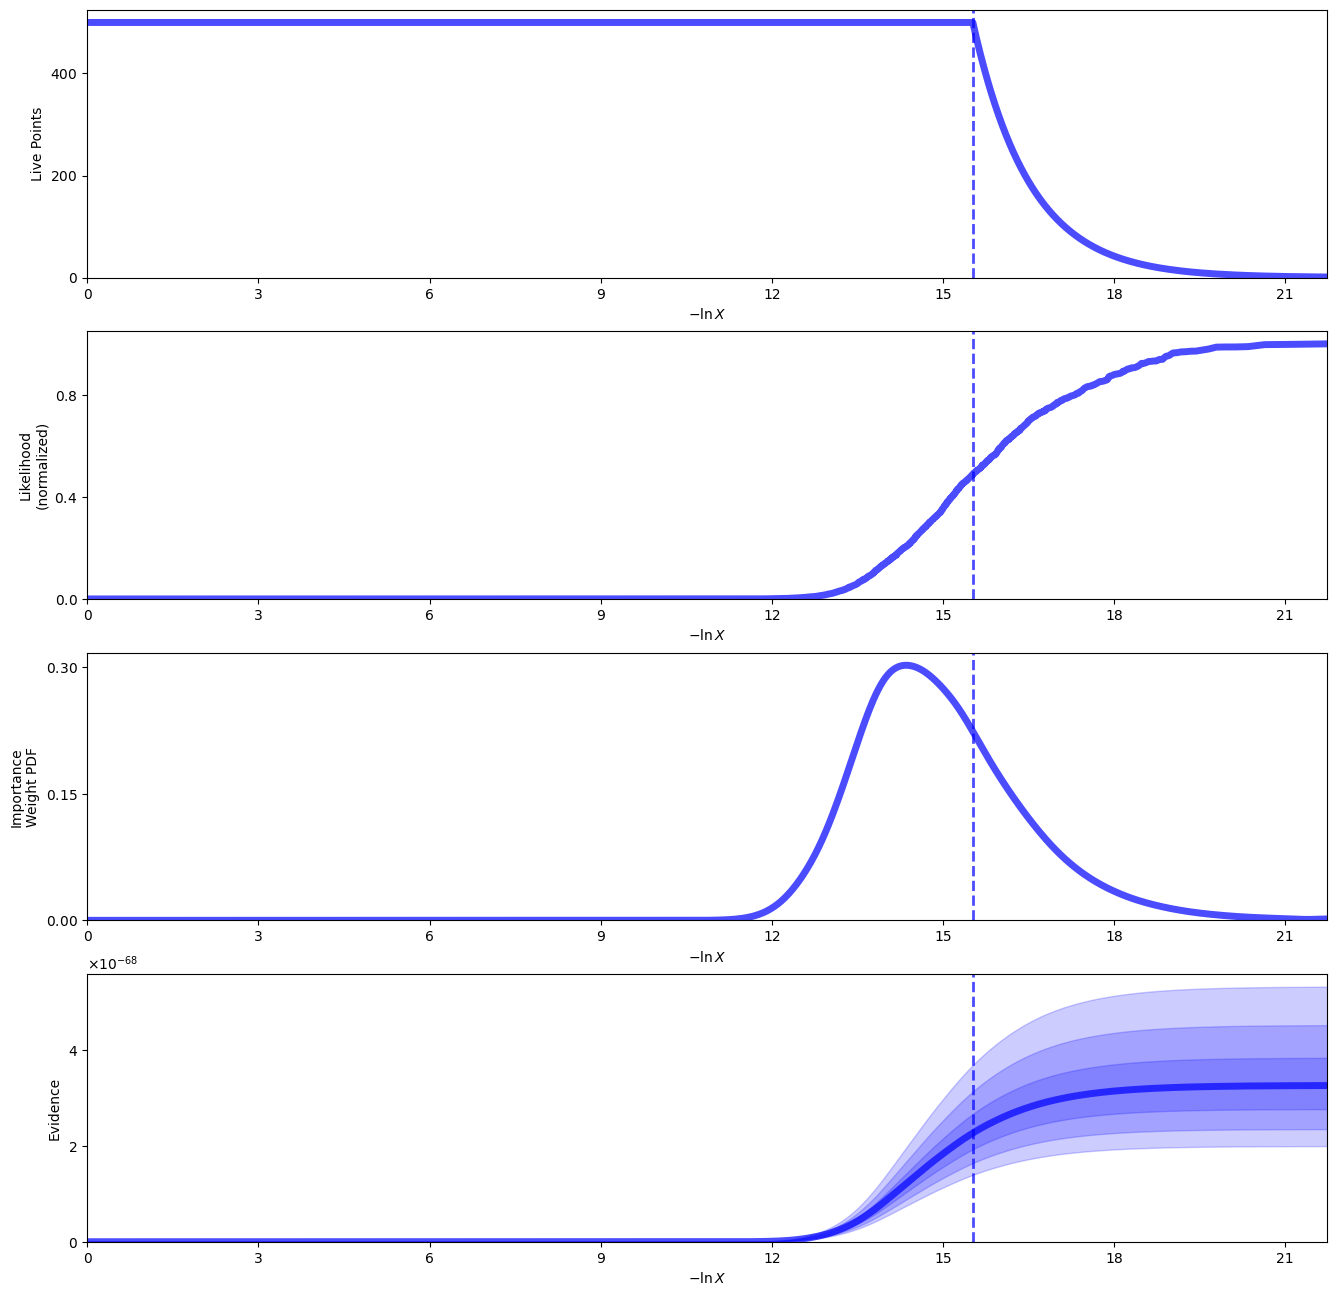

In [ ]:
from dynesty import plotting as dyplot

# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults)

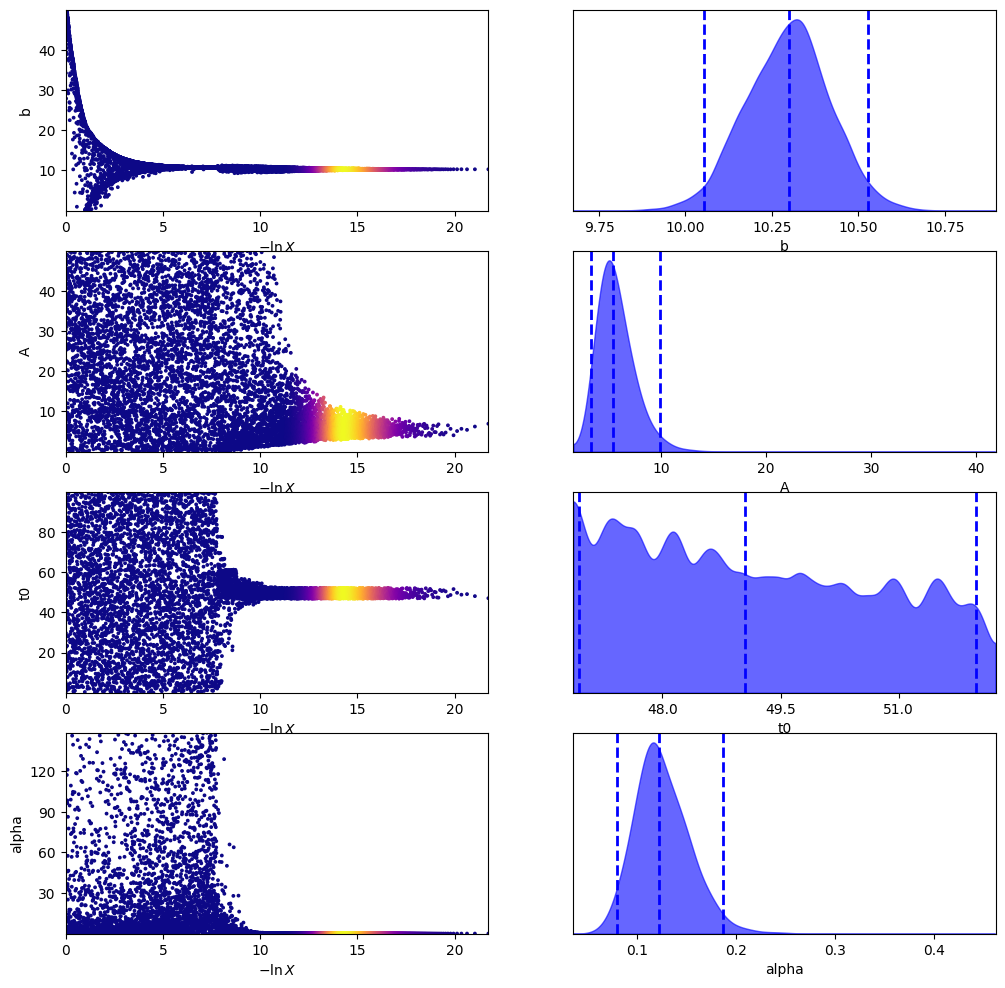

In [ ]:
tfig, taxes = dyplot.traceplot(sresults,labels=labels)

CORNER PLOT

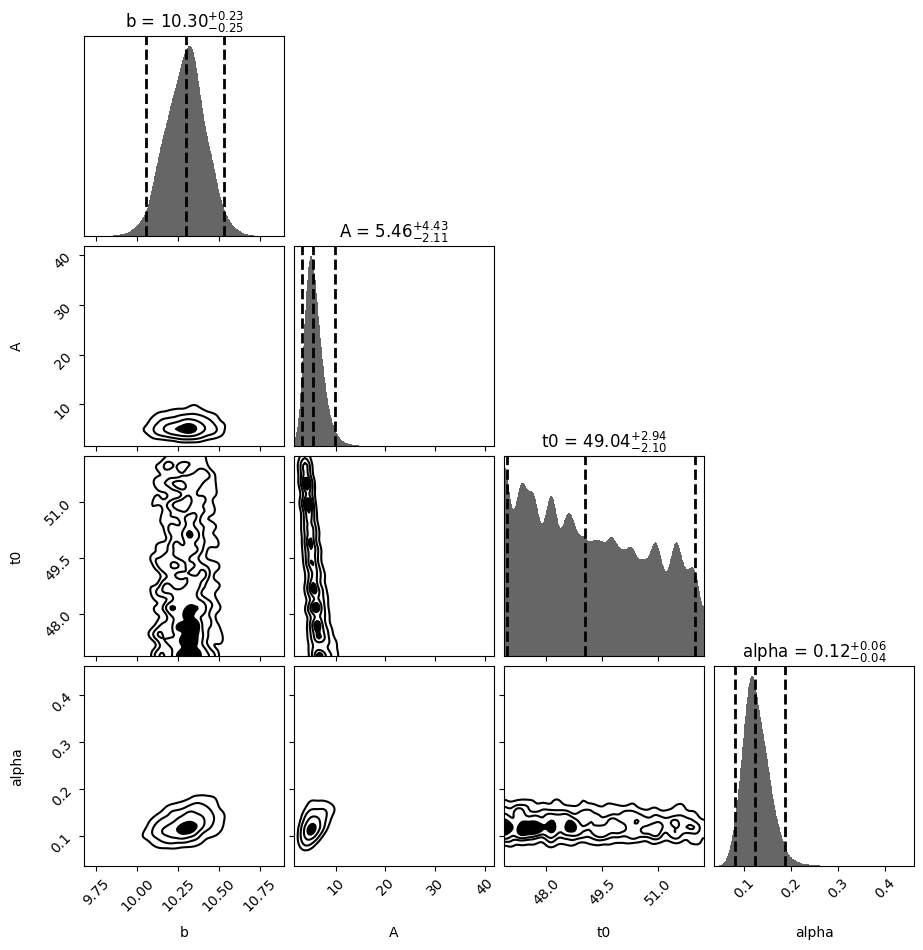

In [ ]:
cfig, caxes = dyplot.cornerplot(sresults,labels=labels, show_titles=True)

PARAMETER CHECK WITH PREVIOUS LECTURE PARAMETERS

---------EMCEE PARAMETER MEDIAN AND CREDIBLE REGION------------

b

median = 10.2907
credible region 90% : 10.0938-10.4858

A

median = 5.3116
credible region 90% : 3.5911-8.6120

t0

median = 49.2247
credible region 90% : 47.0828-51.8850

alpha

median = 0.1215
credible region 90% : 0.0843-0.1758

In [ ]:
from dynesty import utils as dyfunc


# Extract sampling results.
samples = sresults.samples  # samples
weights = np.exp(sresults.logwt - sresults.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples.T,labels):
  quantiles = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights)]
  print(label + '\n: MEDIAN ' + str(quantiles[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles[0][1])+'-'+str(quantiles[0][2]))


# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)




---------PARAMETERS------------
b
: MEDIAN 10.299721006953966
90% CREDIBLE REGION:10.097927290877765-10.489361601439917
A
: MEDIAN 5.45942667424829
90% CREDIBLE REGION:3.599461581433498-8.910756754114624
t0
: MEDIAN 49.04434895883684
90% CREDIBLE REGION:47.034659689726276-51.80695568763921
alpha
: MEDIAN 0.1220821796100983
90% CREDIBLE REGION:0.08550880953881215-0.1747871211644339


8) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

Fit this model usign nested sampling and reasonable priors (this time is up to you to decide...)

In [ ]:
def gaussian(t,theta):
#model definition 4-D
    b,A,t0,sigmaw=theta
    modell = b+A*np.exp(-((t-t0)**2)/2*sigmaw**2)
    return modell

def logL_gauss(theta,y,t,sigma):
#likelihood
  return -0.5*np.sum((((y-gaussian(t,theta))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform_gauss(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    '''b uniform in 0,50
       A uniform in 0,50
       t0 uniform in 0,100
       lnsigmaw uniform in -3,3
    '''
    u1, u2, u3, u4 = u
    p1 = 50.0 * u1   #b
    p2 = 50.0 * u2   #a
    p3 = 100.0 * u3  #t0
    p4 = np.exp(3*(2*u4-1)) #sigmaw

    theta_prior = np.array([p1, p2, p3,p4])
    return theta_prior



Running the sample

In [ ]:
# "Static" nested sampling.
labels = ['b','A','t0','sigmaw']
ndim = 4
sampler_gauss = dynesty.NestedSampler(logL_gauss, ptform_gauss, ndim,logl_args=[flux,time, sigma])
sampler_gauss.run_nested()
sresults_gauss = sampler_gauss.results

 39%|███▉      | 2476/6320 [00:11<00:26, 147.05it/s, bound: 9 | nc: 4 | ncall: 22411 | eff(%): 11.048 | loglstar: -301.389 | logz: -311.491 | dlogz: 144.037 >  0.509]/usr/local/lib/python3.13/dist-packages/dynesty/bounding.py:847: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
 50%|█████     | 2495/4966 [00:11<00:29, 84.68it/s, bound: 10 | nc: 138 | ncall: 22678 | eff(%): 11.002 | loglstar: -296.602 | logz: -306.401 | dlogz: 138.825 >  0.509]/usr/local/lib/python3.13/dist-packages/dynesty/bounding.py:847: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampl

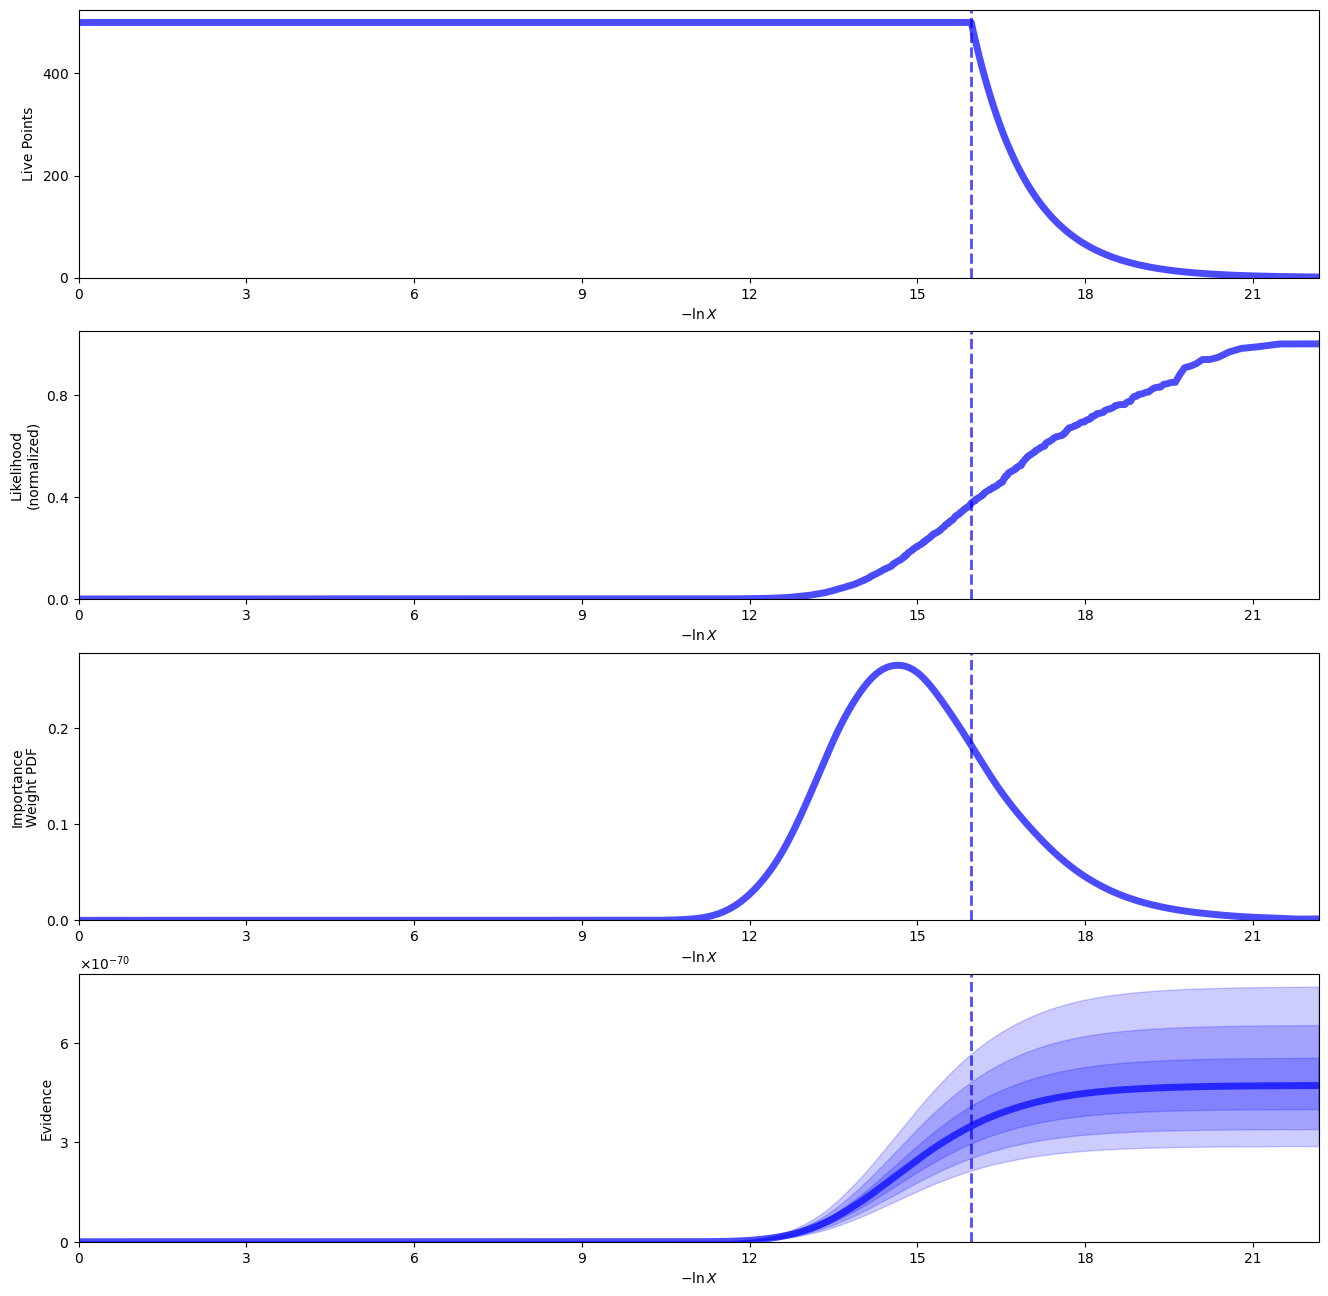

In [ ]:
# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults_gauss)

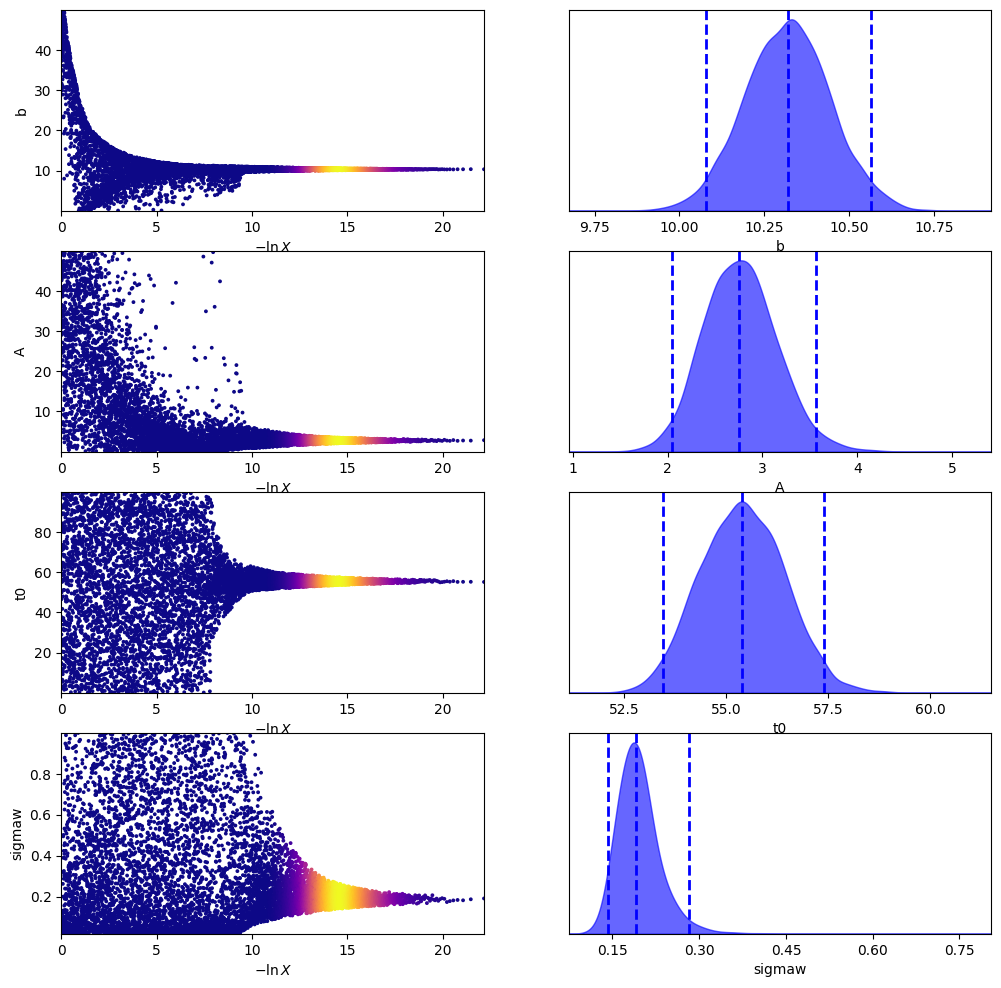

In [ ]:
tfig, taxes = dyplot.traceplot(sresults_gauss,labels=labels)

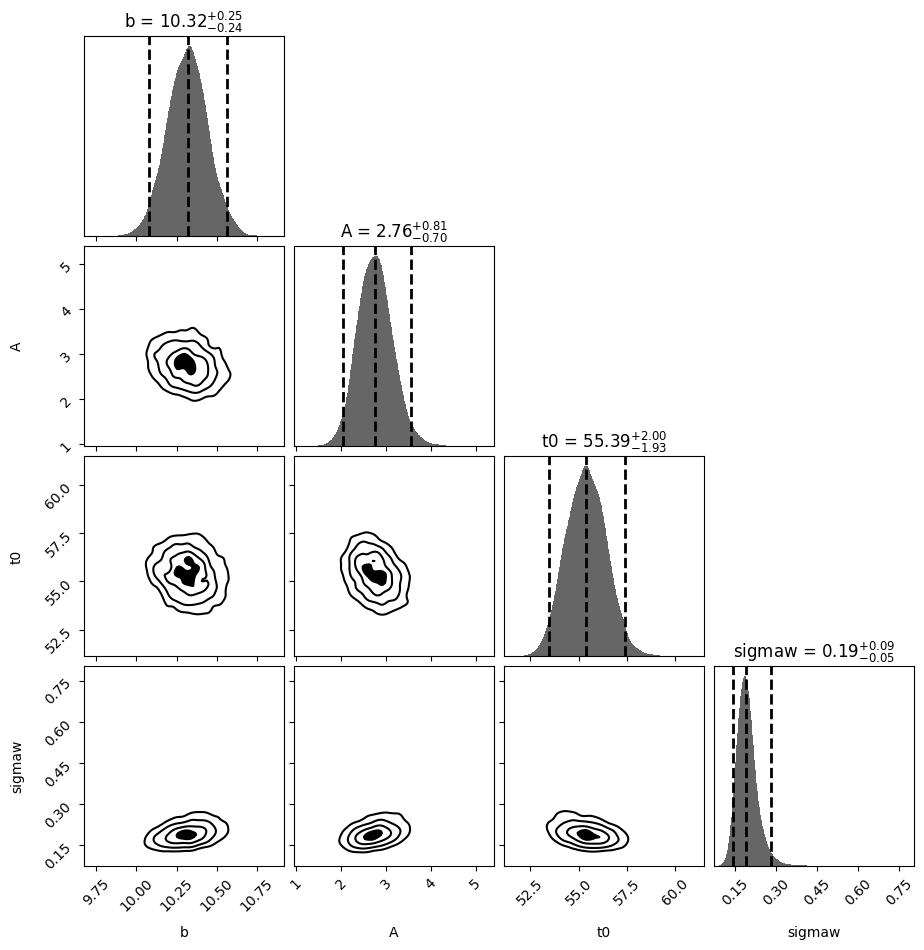

In [ ]:
cfig, caxes = dyplot.cornerplot(sresults_gauss,labels=labels, show_titles=True)

In [ ]:
# Extract sampling results.
samples_gauss = sresults_gauss.samples  # samples
weights_gauss = np.exp(sresults_gauss.logwt - sresults_gauss.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples_gauss.T,labels):
  quantiles_gauss = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights_gauss)]
  print(label + '\n: MEDIAN ' + str(quantiles_gauss[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles_gauss[0][1])+'-'+str(quantiles_gauss[0][2]))


# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)


---------PARAMETERS------------
b
: MEDIAN 10.320229353854506
90% CREDIBLE REGION:10.112482896387814-10.526117817664737
A
: MEDIAN 2.755668221366834
90% CREDIBLE REGION:2.1752944483391876-3.406235433334058
t0
: MEDIAN 55.38957017069173
90% CREDIBLE REGION:53.76216965922198-57.10225114814508
sigmaw
: MEDIAN 0.1909613336760387
90% CREDIBLE REGION:0.14776956666541452-0.2606767590501807


9) Unlike MCMCs, nested sampling provides the Bayesian evidence. Compute the Bayesian evidence for this Gaussian model, and for the original burst model. Which model is the favored description of the data? Express this in terms of the Jeffrey's scale.

In [ ]:
evidence = np.exp(sresults.logz[-1]) #evidence burst
print("Bayesian evidence for model BURST =", evidence)
evidence_gauss= np.exp(sresults_gauss.logz[-1]) #evidence gaussian  #BOTH LOW BECAUSE I FULLY NORMALIZED THE LOGLIKELIHOOD
print("Bayesian evidence for model GAUSSIAN =", evidence_gauss)

print(f'the ratio between the BURST AND GAUSSIAN evidences is :{ evidence/evidence_gauss:.4f}')


Bayesian evidence for model BURST = 3.256091675228551e-68
Bayesian evidence for model GAUSSIAN = 4.720896180286409e-70
the ratio between the BURST AND GAUSSIAN evidences is :68.9719


**very strong evidence in favour of the burst model**